<a href="https://colab.research.google.com/github/SriSudiastini/Restorasi-Citra/blob/main/pcd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving cctv1_blur.jpeg to cctv1_blur.jpeg
File: cctv1_blur.jpeg
Ukuran foto (tinggi, lebar, kanal): (394, 700, 3)


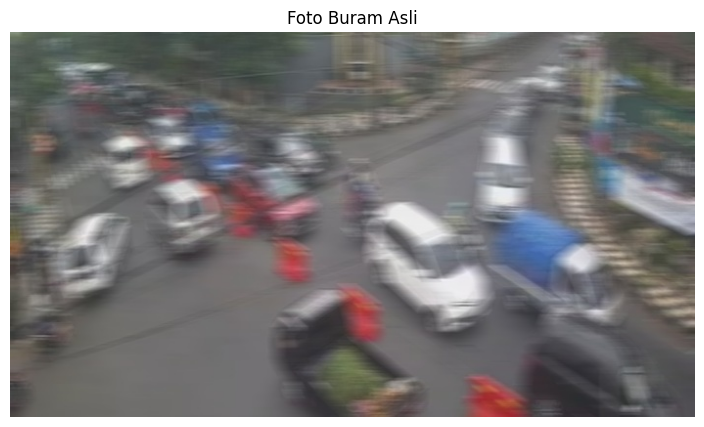

In [ ]:
import io
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from google.colab import files

uploaded = files.upload()
if not uploaded:
    raise ValueError("Belum ada foto yang diupload.")
nama_file = next(iter(uploaded))
foto_pil = ImageOps.exif_transpose(Image.open(io.BytesIO(uploaded[nama_file]))).convert("RGB")
foto_pil.thumbnail((1200, 1200), Image.Resampling.LANCZOS)
original_rgb = np.array(foto_pil, dtype=np.uint8)

print("File:", nama_file)
print("Ukuran foto (tinggi, lebar, kanal):", original_rgb.shape)
plt.figure(figsize=(9, 5))
plt.imshow(original_rgb)
plt.title("Foto Buram Asli")
plt.axis("off")
plt.show()

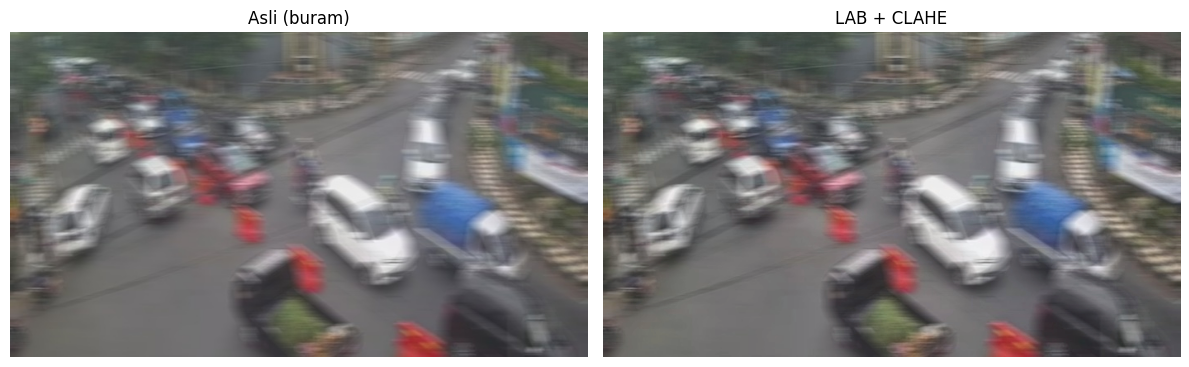

Tahap 2 selesai.


In [ ]:
# Tidak ada proses deblurring atau AI di sini.
lab = cv2.cvtColor(original_rgb, cv2.COLOR_RGB2LAB)
L, kanal_a, kanal_b = cv2.split(lab)

clahe = cv2.createCLAHE(clipLimit=1.3, tileGridSize=(8, 8))
L_clahe = clahe.apply(L)
L_base = cv2.addWeighted(L, 0.7, L_clahe, 0.3, 0)
base = L_base.astype(np.float32)

citra_clahe = cv2.cvtColor(
    cv2.merge([L_base, kanal_a, kanal_b]),
    cv2.COLOR_LAB2RGB
)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(original_rgb); ax[0].set_title('Asli (buram)'); ax[0].axis('off')
ax[1].imshow(citra_clahe); ax[1].set_title('LAB + CLAHE'); ax[1].axis('off')
plt.tight_layout(); plt.show()
print("Tahap 2 selesai.")

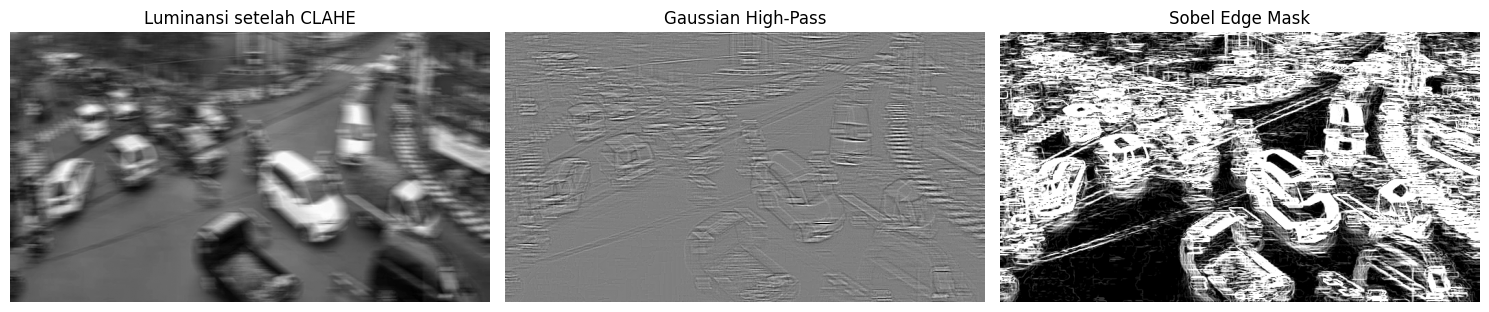

Tahap 3 selesai.


In [ ]:
# membangun fitur detail peta tepi
# Detail frekuensi tinggi pada luminansi
sigma = 1.2
lowpass = cv2.GaussianBlur(base, (0, 0), sigmaX=sigma)
detail = np.clip(base - lowpass, -20.0, 20.0)

# Kekuatan tepi dari gradien Sobel
grad_x = cv2.Sobel(base, cv2.CV_32F, 1, 0, ksize=3)
grad_y = cv2.Sobel(base, cv2.CV_32F, 0, 1, ksize=3)
grad_magnitude = cv2.magnitude(grad_x, grad_y)
edge_mask = np.clip((grad_magnitude - 5.0) / 35.0, 0.0, 1.0)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(L_base, cmap='gray'); ax[0].set_title('Luminansi setelah CLAHE')
ax[1].imshow(detail, cmap='gray', vmin=-20, vmax=20); ax[1].set_title('Gaussian High-Pass')
ax[2].imshow(edge_mask, cmap='gray', vmin=0, vmax=1); ax[2].set_title('Sobel Edge Mask')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()
print("Tahap 3 selesai.")

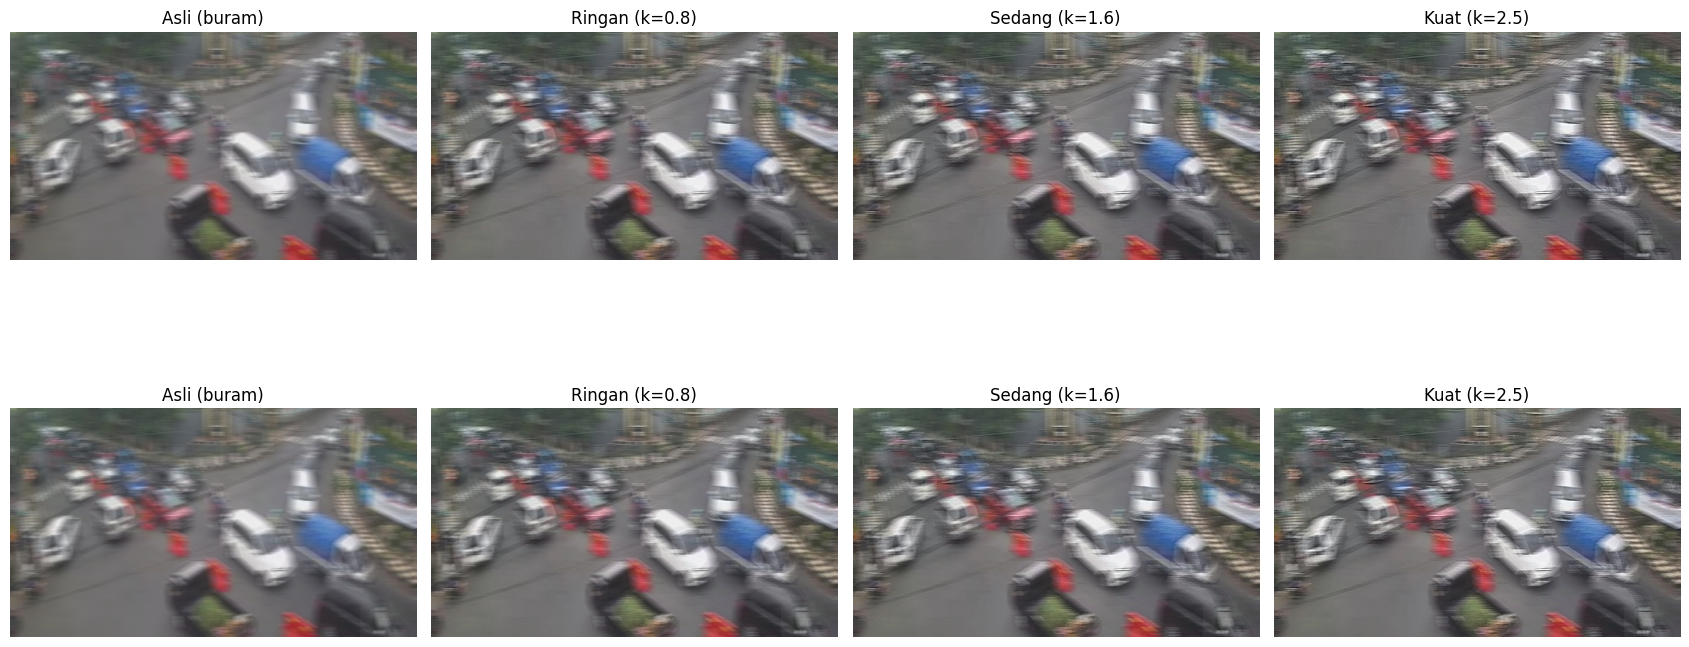

Tahap 4 selesai: masing-masing metode punya 3 hasil.


In [ ]:
# membandingkan
def kembali_ke_rgb(luminansi_float):
    luminansi = np.clip(luminansi_float, 0, 255).astype(np.uint8)
    lab_hasil = cv2.merge([luminansi, kanal_a, kanal_b])
    return cv2.cvtColor(lab_hasil, cv2.COLOR_LAB2RGB)

# Menggunakan kekuatan SAMA agar kedua metode bisa dibandingkan langsung.
pengaturan = {"Ringan": 0.8, "Sedang": 1.6, "Kuat": 2.5}

hasil_unsharp = {}
hasil_edge = {}
for nama, kekuatan in pengaturan.items():
    hasil_unsharp[nama] = kembali_ke_rgb(base + kekuatan * detail)
    hasil_edge[nama] = kembali_ke_rgb(base + kekuatan * detail * edge_mask)

fig, ax = plt.subplots(2, 4, figsize=(17, 9))
for row, (judul, kumpulan) in enumerate([
    ('CLAHE + Unsharp Masking', hasil_unsharp),
    ('CLAHE + Sobel Edge-Aware', hasil_edge)
]):
    ax[row, 0].imshow(original_rgb)
    ax[row, 0].set_title('Asli (buram)')
    for col, nama in enumerate(pengaturan, start=1):
        ax[row, col].imshow(kumpulan[nama])
        ax[row, col].set_title(f'{nama} (k={pengaturan[nama]})')
    ax[row, 0].set_ylabel(judul)
for a in ax.flat: a.axis('off')
plt.tight_layout(); plt.show()
print('Tahap 4 selesai: masing-masing metode punya 3 hasil.')

=== HASIL EVALUASI ===
           Metode  Variansi Laplacian  Tenengrad  Perubahan Laplacian (%)  Perubahan Tenengrad (%)
     Asli (buram)              638.01    1758.56                     0.00                     0.00
       CLAHE saja              944.22    2444.00                    48.00                    38.98
   Unsharp Ringan             2500.68    4021.92                   291.95                   128.71
   Unsharp Sedang             4829.19    6202.90                   656.91                   252.73
     Unsharp Kuat             8352.59    9356.06                  1209.16                   432.03
Edge-Aware Ringan             2189.18    3710.68                   243.13                   111.01
Edge-Aware Sedang             4019.72    5404.17                   530.04                   207.31
  Edge-Aware Kuat             6781.36    7816.29                   962.89                   344.47


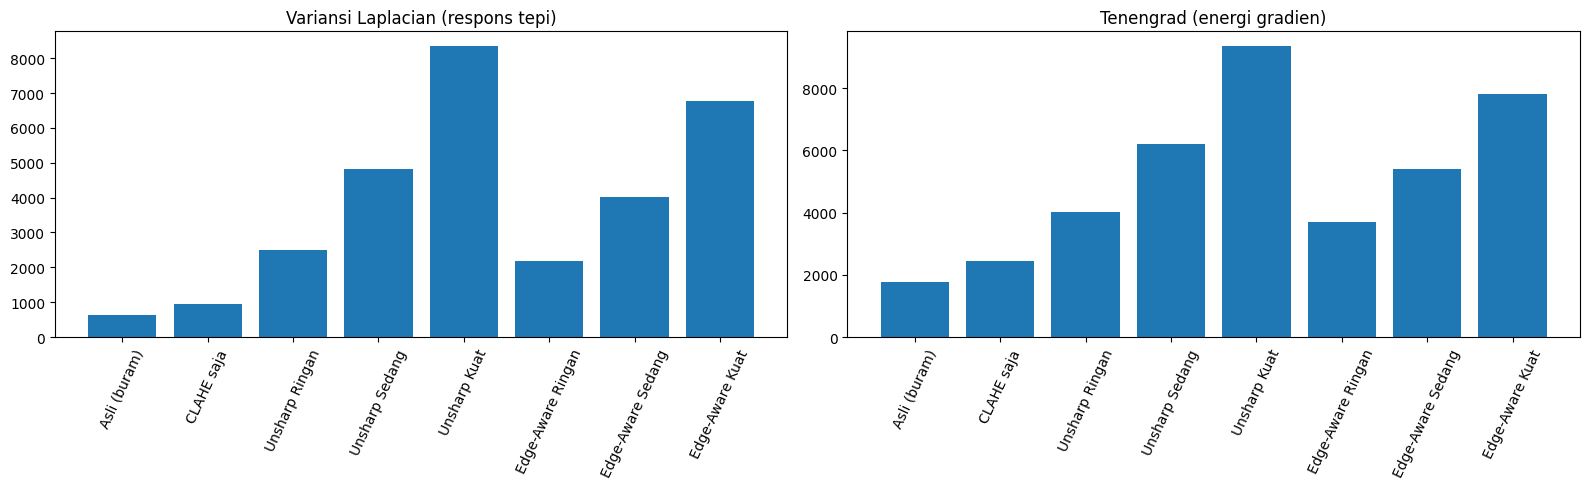

Tahap 5 selesai.


In [ ]:
def ukur_ketegasan_tepi(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    lap = cv2.Laplacian(gray, cv2.CV_32F, ksize=3)
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    return float(lap.var()), float(np.mean(gx**2 + gy**2))

semua_gambar = {'Asli (buram)': original_rgb, 'CLAHE saja': citra_clahe}
for nama in pengaturan:
    semua_gambar[f'Unsharp {nama}'] = hasil_unsharp[nama]
for nama in pengaturan:
    semua_gambar[f'Edge-Aware {nama}'] = hasil_edge[nama]

data = []
for nama, gambar in semua_gambar.items():
    laplacian, tenengrad = ukur_ketegasan_tepi(gambar)
    data.append({'Metode': nama, 'Variansi Laplacian': laplacian, 'Tenengrad': tenengrad})

df_evaluasi = pd.DataFrame(data)
lap_awal = df_evaluasi.loc[0, 'Variansi Laplacian']
ten_awal = df_evaluasi.loc[0, 'Tenengrad']
df_evaluasi['Perubahan Laplacian (%)'] = 100 * (df_evaluasi['Variansi Laplacian'] / max(lap_awal, 1e-9) - 1)
df_evaluasi['Perubahan Tenengrad (%)'] = 100 * (df_evaluasi['Tenengrad'] / max(ten_awal, 1e-9) - 1)
print('=== HASIL EVALUASI ===')
print(df_evaluasi.round(2).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].bar(df_evaluasi['Metode'], df_evaluasi['Variansi Laplacian'])
ax[0].set_title('Variansi Laplacian (respons tepi)')
ax[1].bar(df_evaluasi['Metode'], df_evaluasi['Tenengrad'])
ax[1].set_title('Tenengrad (energi gradien)')
for a in ax: a.tick_params(axis='x', labelrotation=65)
plt.tight_layout(); plt.show()
print('Tahap 5 selesai.')

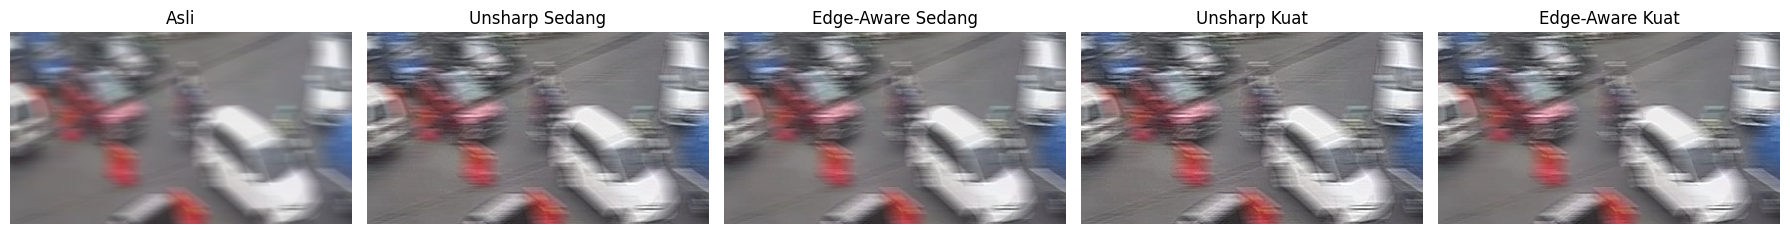

Tahap 6 selesai. Periksa artefak, bukan sekadar skor tertinggi.


In [ ]:
h, w = original_rgb.shape[:2]
y1, y2 = int(h * 0.25), int(h * 0.75)
x1, x2 = int(w * 0.25), int(w * 0.75)

zoom_set = {
    'Asli': original_rgb,
    'Unsharp Sedang': hasil_unsharp['Sedang'],
    'Edge-Aware Sedang': hasil_edge['Sedang'],
    'Unsharp Kuat': hasil_unsharp['Kuat'],
    'Edge-Aware Kuat': hasil_edge['Kuat'],
}
fig, ax = plt.subplots(1, len(zoom_set), figsize=(18, 5))
for a, (nama, gambar) in zip(ax, zoom_set.items()):
    a.imshow(gambar[y1:y2, x1:x2])
    a.set_title(nama)
    a.axis('off')
plt.tight_layout(); plt.show()
print('Tahap 6 selesai. Periksa artefak, bukan sekadar skor tertinggi.')